# Penguins: clustering

## Cargar el dataset


In [61]:
import pandas as pd

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
df_original = pd.read_csv(url)
df = df_original.copy()
df.head()


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [62]:
numeric_features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g",
]
df = df[numeric_features].copy()
df.head()


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
3,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0


In [63]:
missing_values = df.isna().sum().rename("valores_faltantes")
display(missing_values.to_frame())
print(f"Total de valores faltantes: {missing_values.sum()}")
print(f"Filas con valores faltantes: {df.isna().any(axis=1).sum()}")


,valores_faltantes
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2


Total de valores faltantes: 8
Filas con valores faltantes: 2


In [64]:
rows_before = len(df)
df = df.dropna().copy()
print(f"Observaciones eliminadas: {rows_before - len(df)}")
print(f"Observaciones restantes: {len(df)}")
print(f"Valores faltantes restantes: {df.isna().sum().sum()}")
df.head()


Observaciones eliminadas: 2
Observaciones restantes: 342
Valores faltantes restantes: 0


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
4,36.7,19.3,193.0,3450.0
5,39.3,20.6,190.0,3650.0


In [65]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df),
    columns=df.columns,
    index=df.index,
)
df_scaled.head()


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,-0.884499,0.785449,-1.418347,-0.564142
1,-0.811126,0.126188,-1.062250,-0.501703
2,-0.664380,0.430462,-0.421277,-1.188532
4,-1.324737,1.089724,-0.563715,-0.938776
5,-0.847812,1.748985,-0.777373,-0.689020


# Kmeans

,k,inercia
0,1,1368.000000
1,2,565.707645
2,3,379.392503
3,4,300.399536
4,5,232.604895
5,6,204.392600
6,7,187.028921
7,8,170.980041
8,9,158.995983
9,10,149.362787


K sugerido por el método del codo: 3


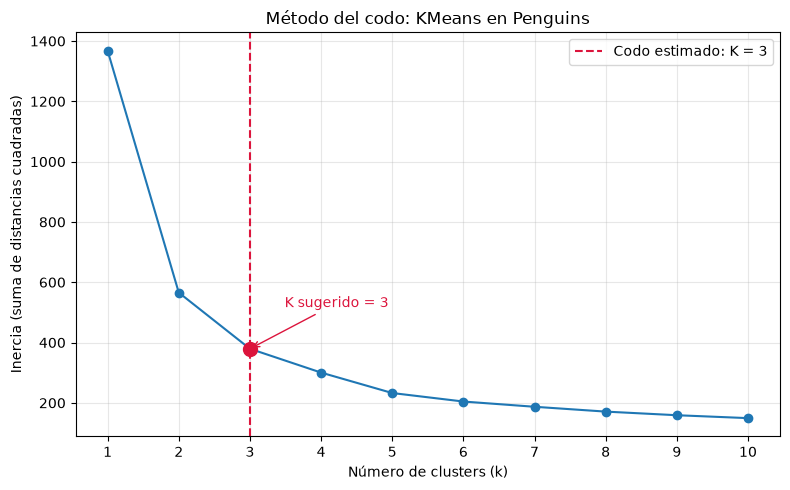

In [66]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

k_values = range(1, 11)
inertias = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    inertias.append(kmeans.inertia_)

elbow_results = pd.DataFrame({"k": list(k_values), "inercia": inertias})
display(elbow_results)

# Codo estimado: máxima distancia a la recta entre los extremos.
# Normalizamos ambos ejes para que sus unidades no afecten la selección.
k_array = elbow_results["k"].to_numpy(dtype=float)
inertia_array = elbow_results["inercia"].to_numpy()
k_normalized = (k_array - k_array.min()) / np.ptp(k_array)
inertia_range = np.ptp(inertia_array)
if inertia_range == 0:
    raise ValueError("La inercia es constante: no se puede identificar un codo.")
inertia_normalized = (inertia_array - inertia_array.min()) / inertia_range
line_inertia = 1 - k_normalized
elbow_distances = np.abs(line_inertia - inertia_normalized) / np.sqrt(2)
elbow_index = int(np.argmax(elbow_distances[1:-1])) + 1
ideal_k = int(k_array[elbow_index])
ideal_inertia = inertia_array[elbow_index]
print(f"K sugerido por el método del codo: {ideal_k}")
# Es una estimación geométrica, no una garantía de un K óptimo.


fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(elbow_results["k"], elbow_results["inercia"], marker="o")
ax.axvline(ideal_k, color="crimson", linestyle="--", label=f"Codo estimado: K = {ideal_k}")
ax.scatter(ideal_k, ideal_inertia, color="crimson", s=100, zorder=5)
ax.annotate(
    f"K sugerido = {ideal_k}",
    xy=(ideal_k, ideal_inertia), xytext=(25, 30),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "crimson"},
    color="crimson",
)
ax.legend()
ax.set_xticks(list(k_values))
ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Inercia (suma de distancias cuadradas)")
ax.set_title("Método del codo: KMeans en Penguins")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


,k,silhouette_score
0,2,0.531540
1,3,0.447219
2,4,0.399584
3,5,0.378892
4,6,0.367996
5,7,0.330913
6,8,0.296052
7,9,0.283433
8,10,0.284562


Mejor K por silhouette: 2
Silhouette score: 0.5315


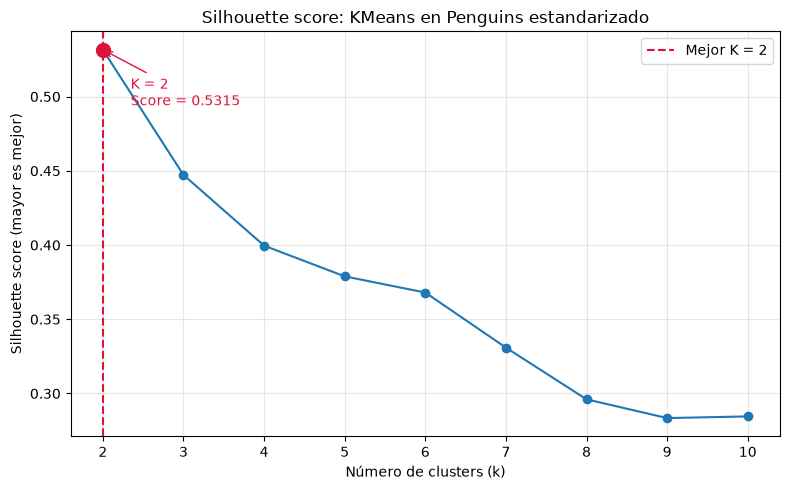

In [67]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Silhouette requiere al menos 2 clusters y menos clusters que observaciones.
silhouette_k_values = range(2, min(10, len(df_scaled) - 1) + 1)
silhouette_scores = []

for k in silhouette_k_values:
    silhouette_model = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = silhouette_model.fit_predict(df_scaled)
    silhouette_scores.append(silhouette_score(df_scaled, cluster_labels))

silhouette_results = pd.DataFrame({
    "k": list(silhouette_k_values),
    "silhouette_score": silhouette_scores,
})
display(silhouette_results)
best_silhouette_row = silhouette_results.loc[
    silhouette_results["silhouette_score"].idxmax()
]
best_silhouette_k = int(best_silhouette_row["k"])
best_silhouette_score = float(best_silhouette_row["silhouette_score"])
print(f"Mejor K por silhouette: {best_silhouette_k}")
print(f"Silhouette score: {best_silhouette_score:.4f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(silhouette_results["k"], silhouette_results["silhouette_score"], marker="o")
ax.axvline(
    best_silhouette_k, color="crimson", linestyle="--",
    label=f"Mejor K = {best_silhouette_k}",
)
ax.scatter(best_silhouette_k, best_silhouette_score, color="crimson", s=100, zorder=5)
ax.annotate(
    f"K = {best_silhouette_k}\nScore = {best_silhouette_score:.4f}",
    xy=(best_silhouette_k, best_silhouette_score), xytext=(20, -40),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "crimson"},
    color="crimson",
)
ax.set_xticks(list(silhouette_k_values))
ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Silhouette score (mayor es mejor)")
ax.set_title("Silhouette score: KMeans en Penguins estandarizado")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


In [68]:
# Elegimos K = 3 según el codo estimado de la curva de inercia.
# Silhouette es un criterio complementario y puede sugerir otro K.
best_k = 3
print(f"K seleccionado: {best_k}")
print(f"K sugerido por el codo: {ideal_k}")
print(f"K con mayor silhouette: {best_silhouette_k}")


K seleccionado: 3
K sugerido por el codo: 3
K con mayor silhouette: 2


In [69]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans_model = KMeans(n_clusters=best_k, random_state=42, n_init=10)
cluster_labels = kmeans_model.fit_predict(df_scaled)

# Conservamos las cuatro features originales y añadimos las etiquetas en una copia.
df_clusters = df.copy()
df_clusters["cluster"] = cluster_labels

display(df_clusters.head())
display(df_clusters["cluster"].value_counts().sort_index().rename("observaciones").to_frame())
print(f"K utilizado: {kmeans_model.n_clusters}")
print(f"Inercia: {kmeans_model.inertia_:.4f}")
print(f"Silhouette score: {silhouette_score(df_scaled, cluster_labels):.4f}")


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,cluster
0,39.1,18.7,181.0,3750.0,2
1,39.5,17.4,186.0,3800.0,2
2,40.3,18.0,195.0,3250.0,2
4,36.7,19.3,193.0,3450.0,2
5,39.3,20.6,190.0,3650.0,2


,observaciones
cluster,
0,87
1,123
2,132


K utilizado: 3
Inercia: 379.3925
Silhouette score: 0.4472


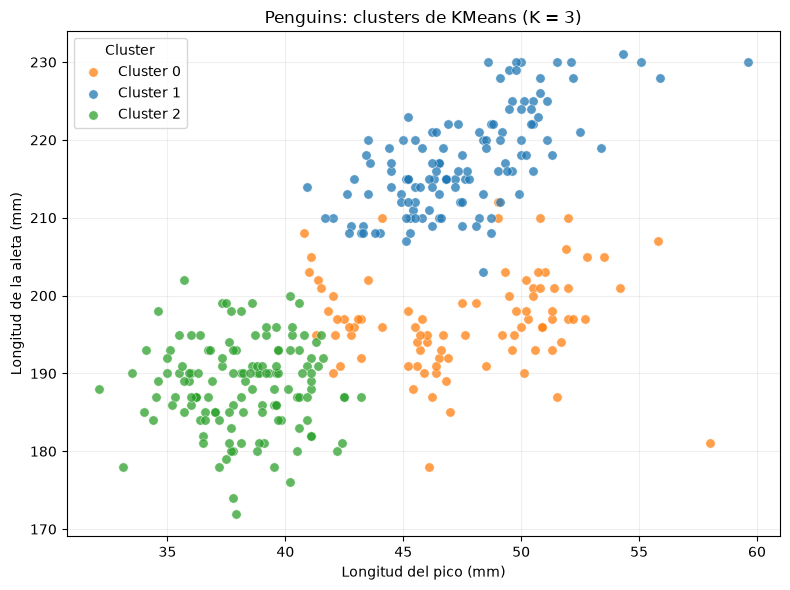

In [70]:
import matplotlib.pyplot as plt

x_feature = "bill_length_mm"
y_feature = "flipper_length_mm"

fig, ax = plt.subplots(figsize=(8, 6))
cluster_ids = sorted(df_clusters["cluster"].unique())
k = kmeans_model.n_clusters
if k == 3:
    colors = ["tab:orange", "tab:blue", "tab:green"]
else:
    colors = [plt.get_cmap("turbo")(i / max(k - 1, 1)) for i in range(k)]

for color_index, cluster_id in enumerate(cluster_ids):
    cluster_data = df_clusters.loc[df_clusters["cluster"] == cluster_id]
    ax.scatter(
        cluster_data[x_feature], cluster_data[y_feature],
        color=colors[color_index], label=f"Cluster {cluster_id}",
        alpha=0.75, s=45, edgecolors="white", linewidths=0.4,
    )

ax.set_xlabel("Longitud del pico (mm)")
ax.set_ylabel("Longitud de la aleta (mm)")
ax.set_title(f"Penguins: clusters de KMeans (K = {kmeans_model.n_clusters})")
ax.legend(title="Cluster")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
# Las etiquetas provienen del KMeans ajustado con las cuatro features estandarizadas.


# HCA

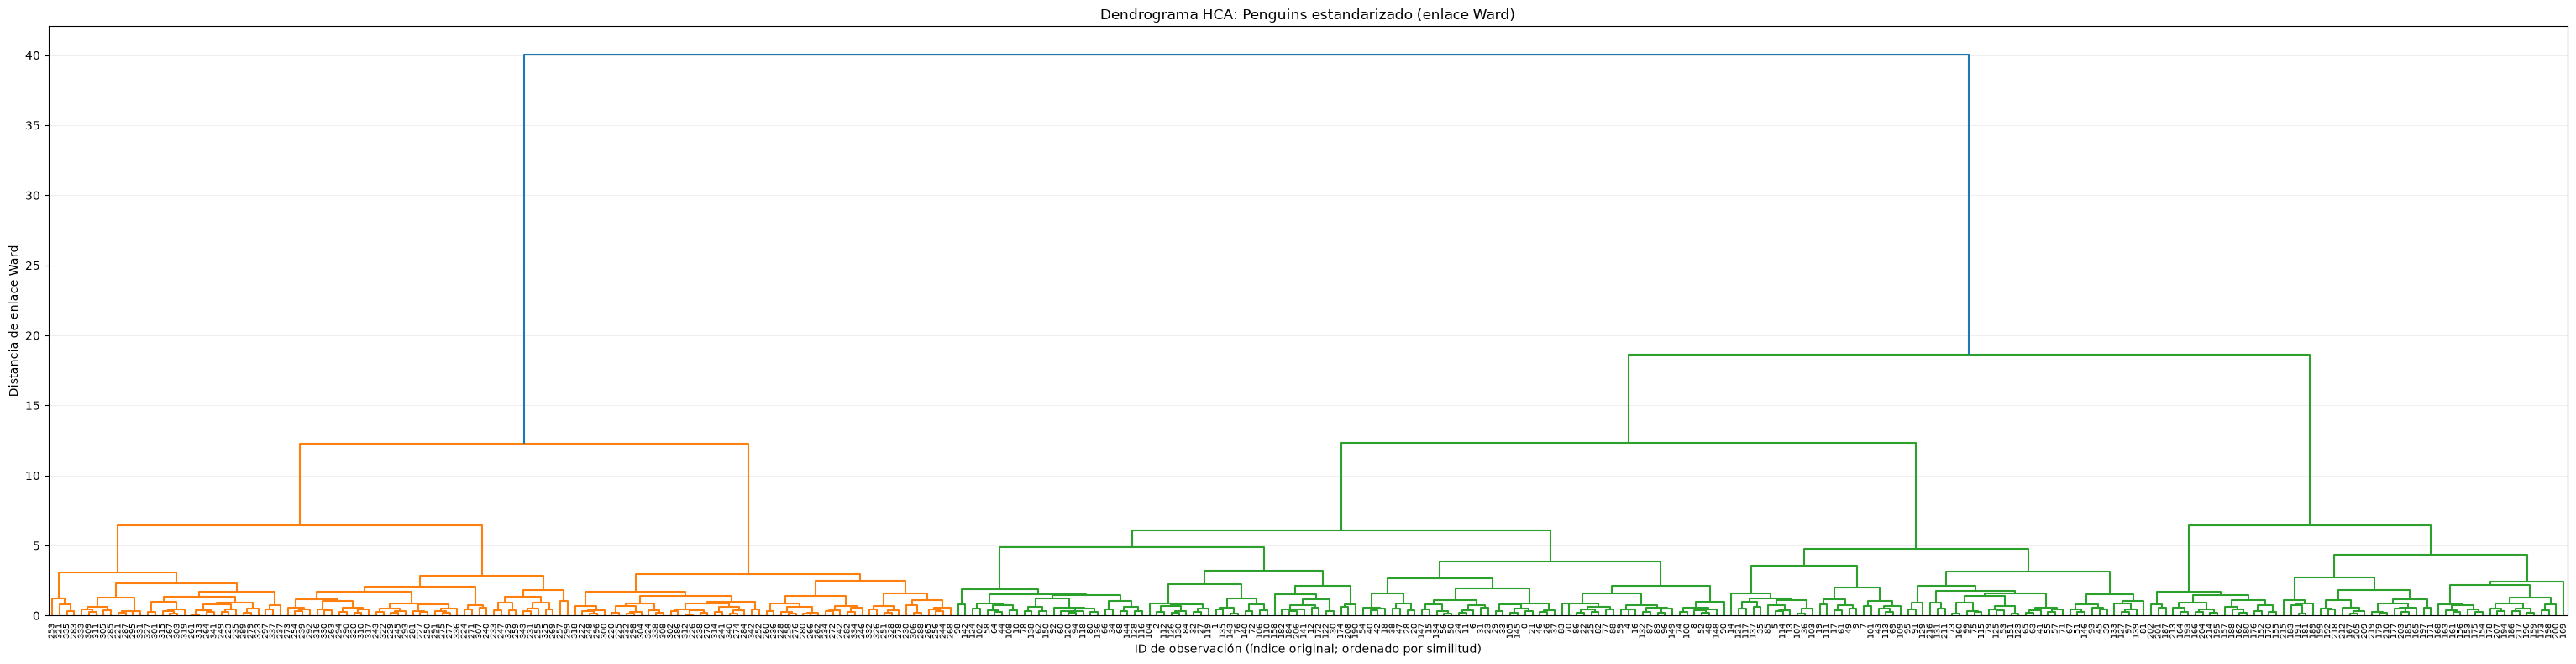

In [71]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

# Mismo preprocesamiento que KMeans: cuatro features numéricas,
# sin valores faltantes y estandarizadas con StandardScaler.
hca_linkage = linkage(
    df_scaled,
    method="ward",
    metric="euclidean",
    optimal_ordering=True,
)

# Los IDs conservan el índice original, incluso tras eliminar filas incompletas.
observation_ids = df_scaled.index.astype(str).tolist()
fig, ax = plt.subplots(figsize=(max(16, len(observation_ids) * 0.09), 8))
dendrogram(
    hca_linkage,
    ax=ax,
    labels=observation_ids,
    leaf_rotation=90,
    leaf_font_size=7,
)
ax.set_title("Dendrograma HCA: Penguins estandarizado (enlace Ward)")
ax.set_xlabel("ID de observación (índice original; ordenado por similitud)")
ax.set_ylabel("Distancia de enlace Ward")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig("penguins_hca_dendrogram.png", dpi=300, bbox_inches="tight")
plt.show()


## Comparación de métodos de enlace

Se mantienen las cuatro features estandarizadas y la distancia euclídea. Las alturas tienen escalas propias de cada método; `centroid` y `median` pueden presentar inversiones en las alturas de fusión.


Guardado: penguins_dendrograms/penguins_dendrogram_single.png


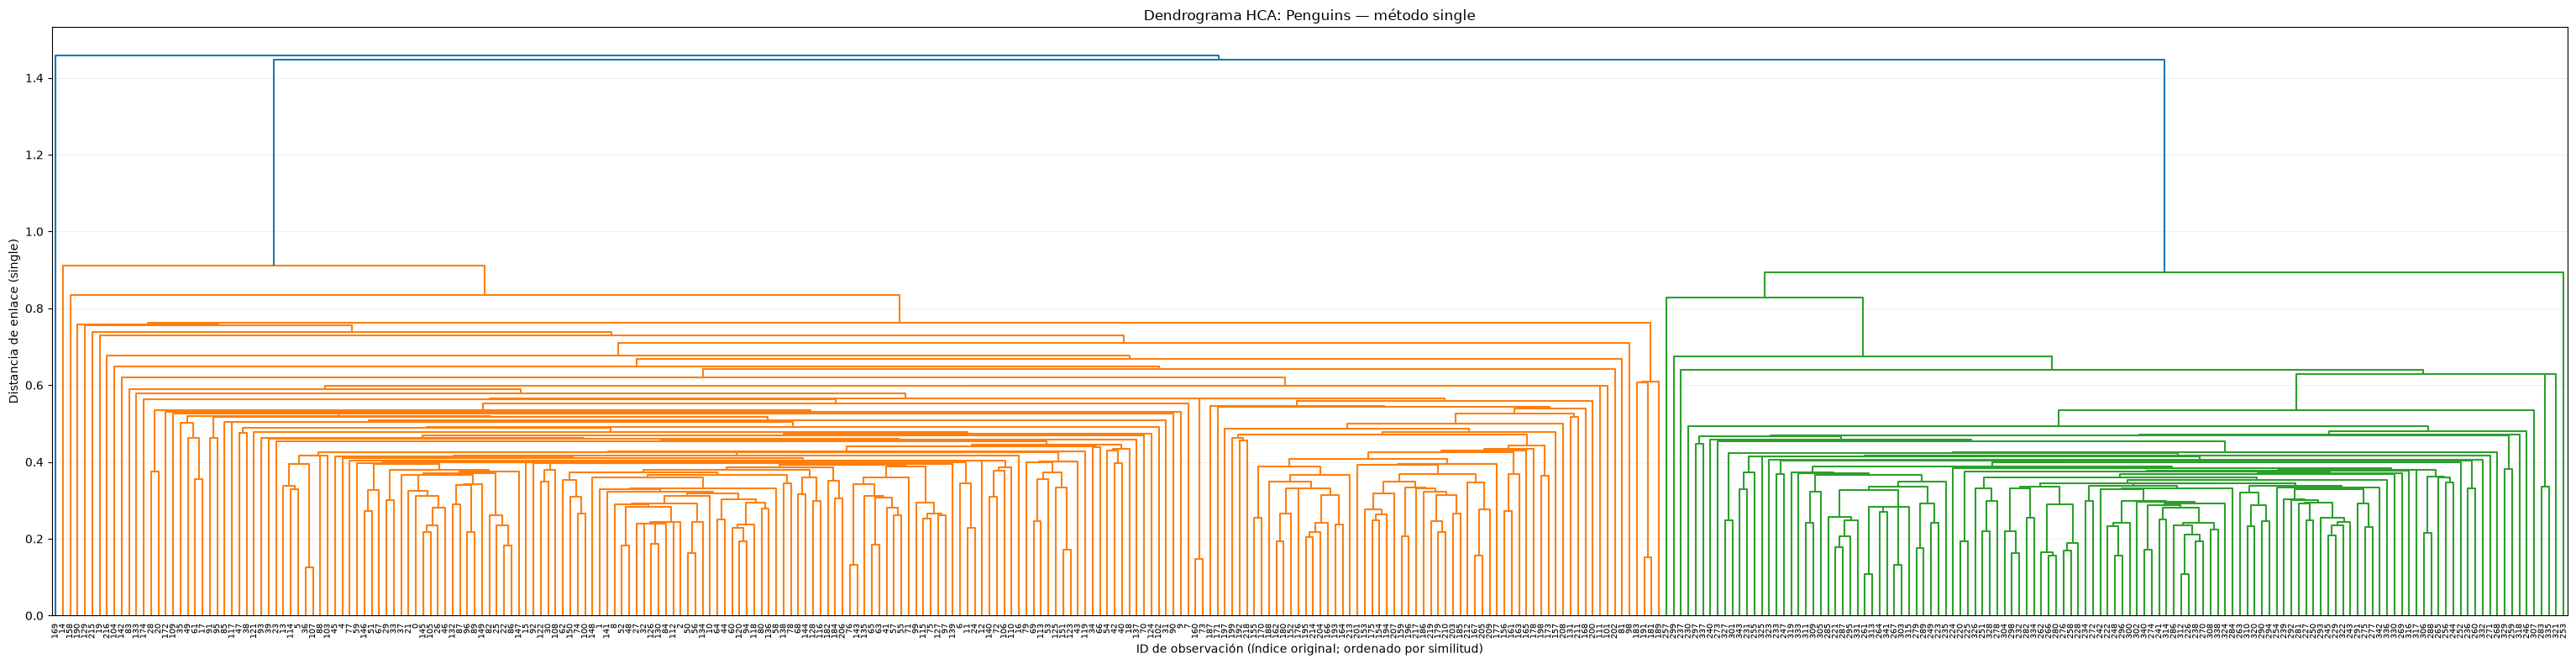

Guardado: penguins_dendrograms/penguins_dendrogram_complete.png


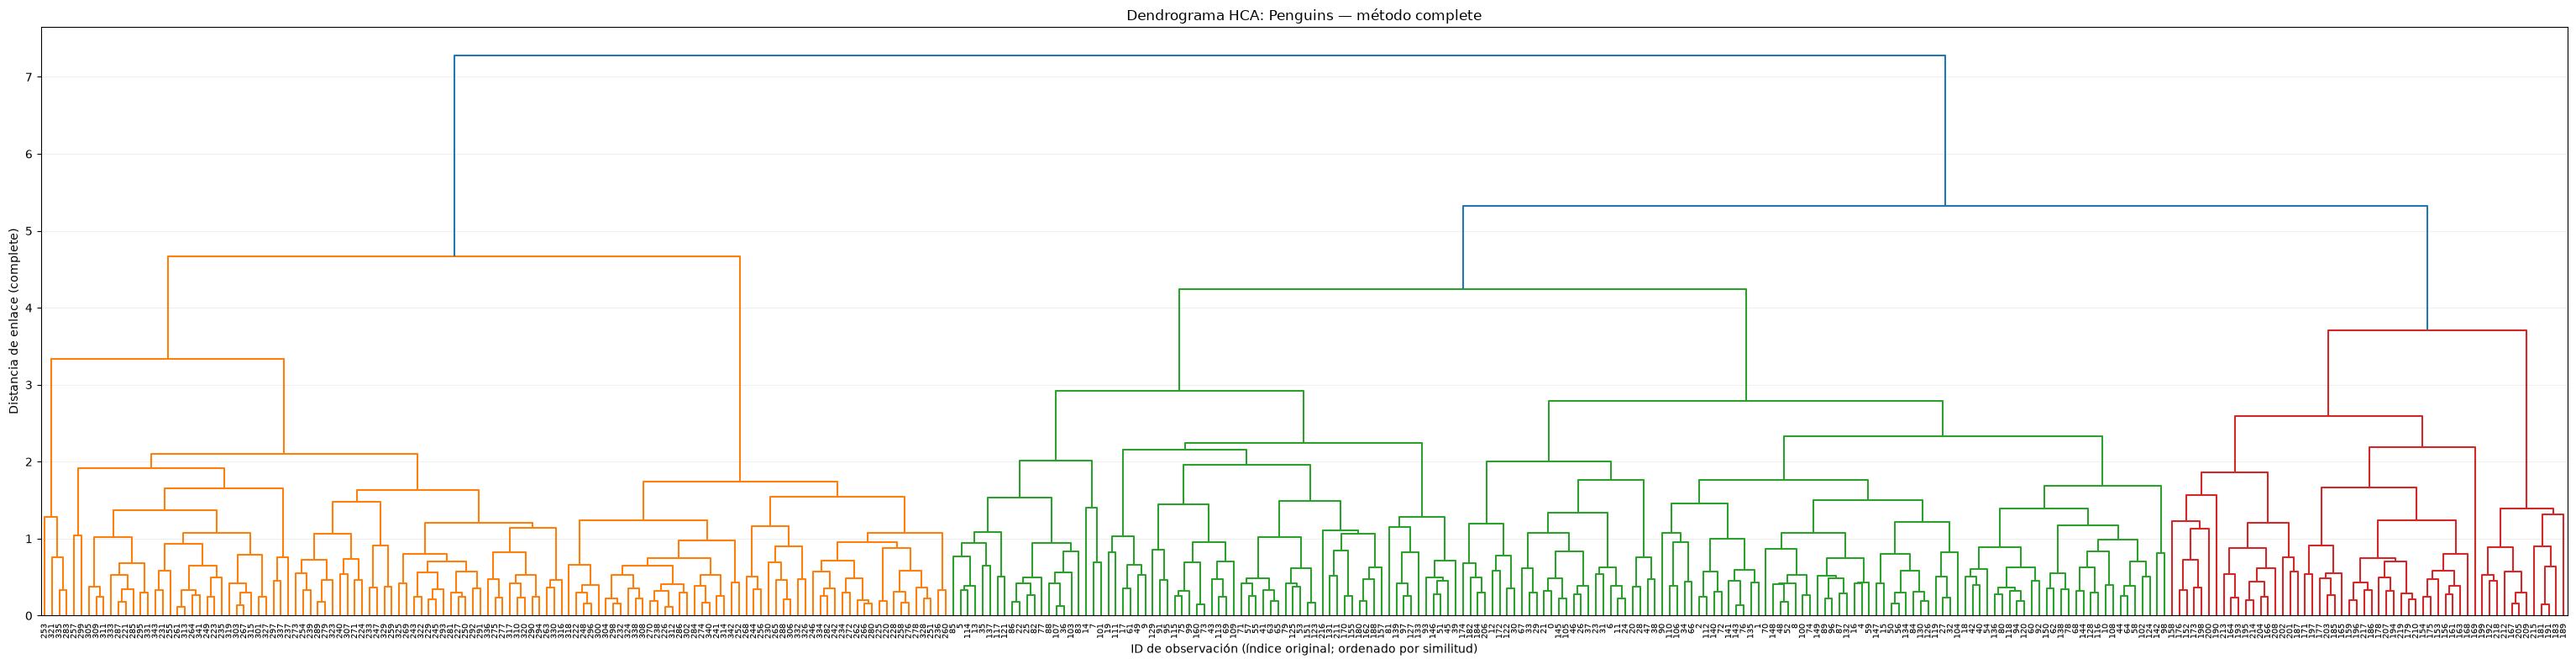

Guardado: penguins_dendrograms/penguins_dendrogram_average.png


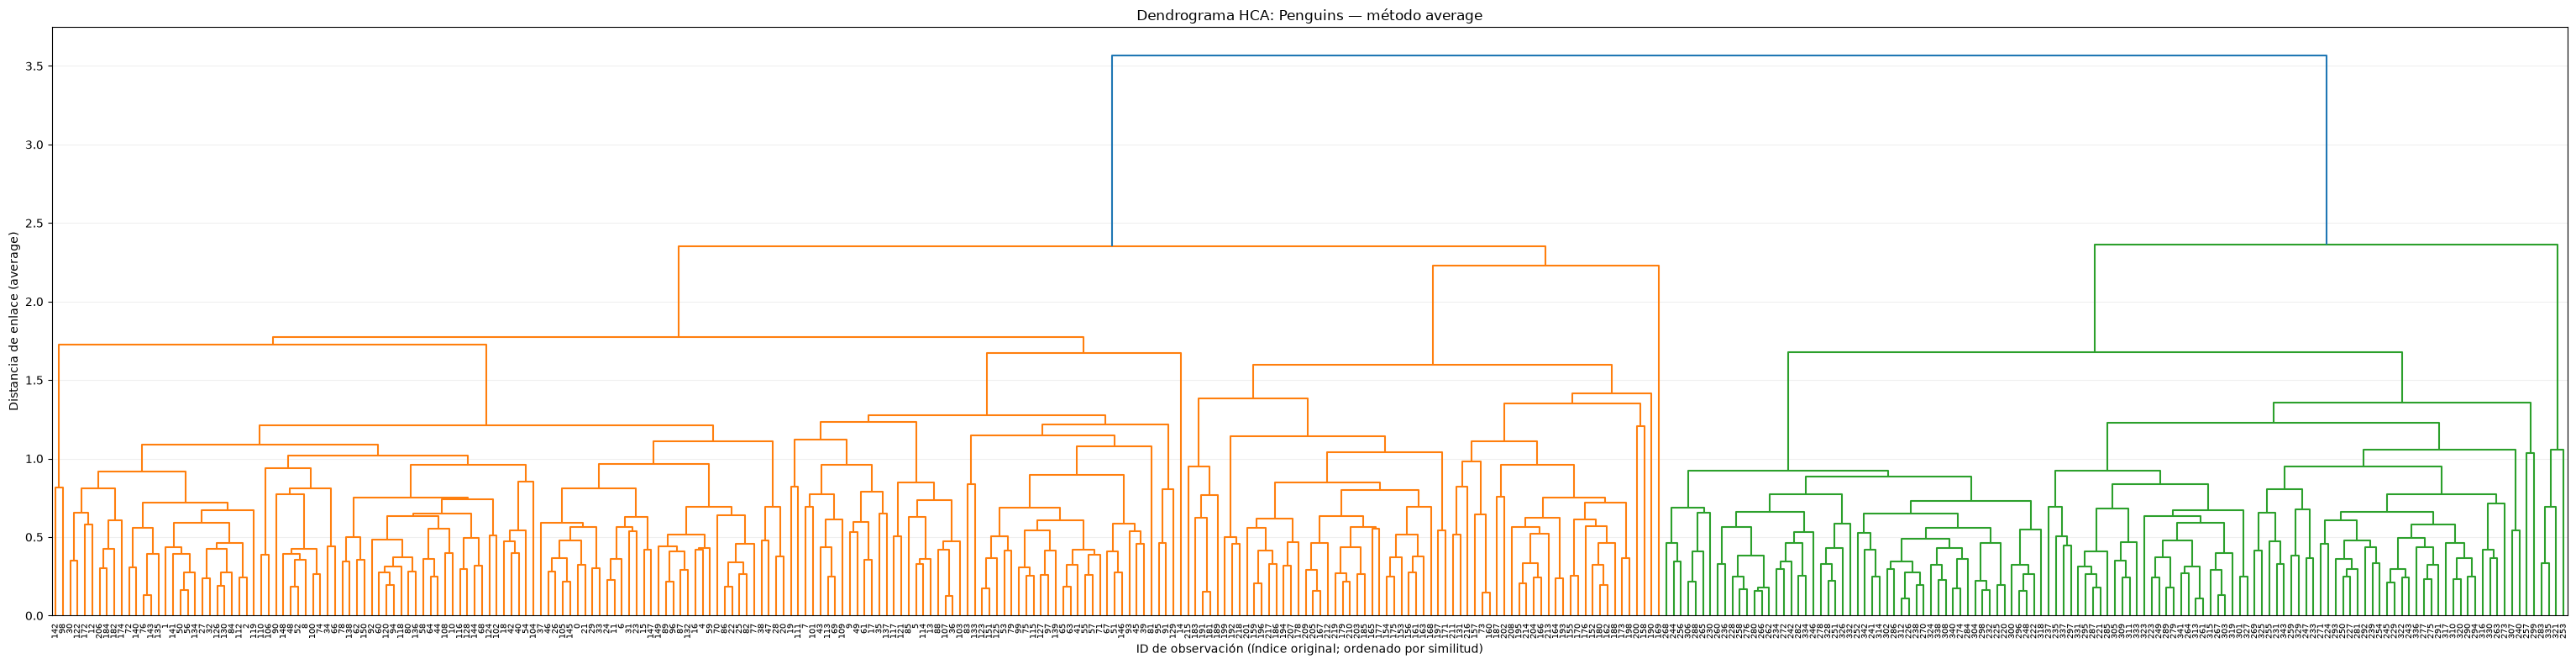

Guardado: penguins_dendrograms/penguins_dendrogram_weighted.png


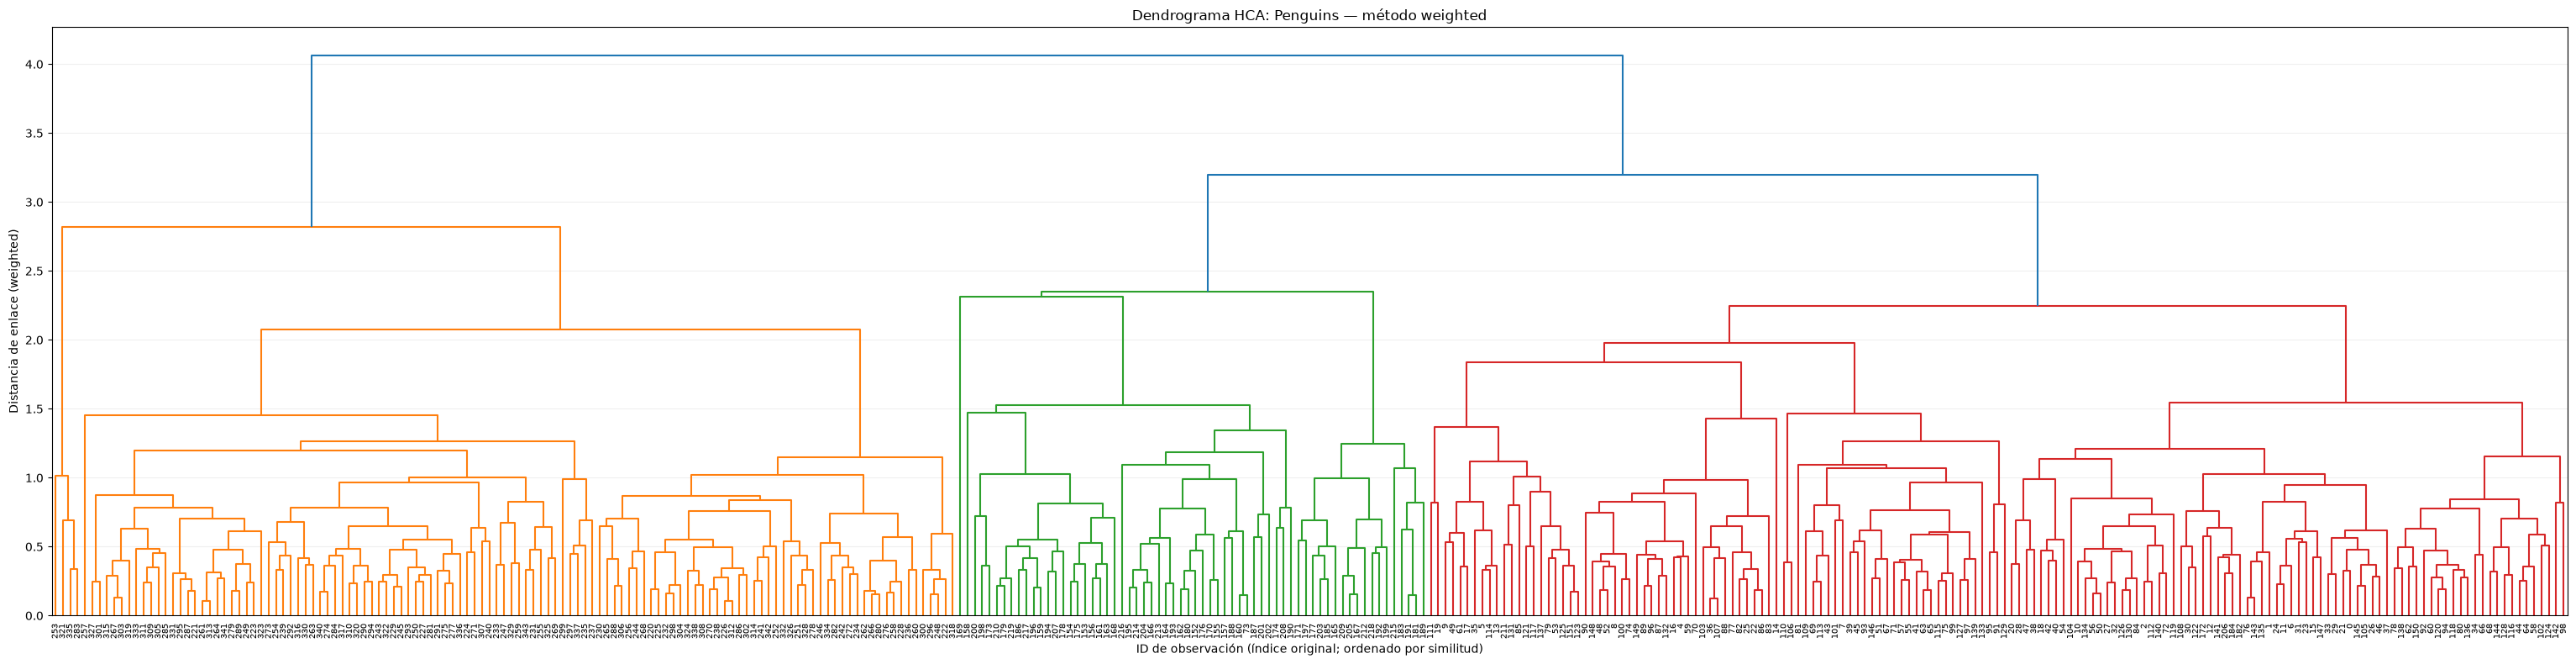

Guardado: penguins_dendrograms/penguins_dendrogram_centroid.png


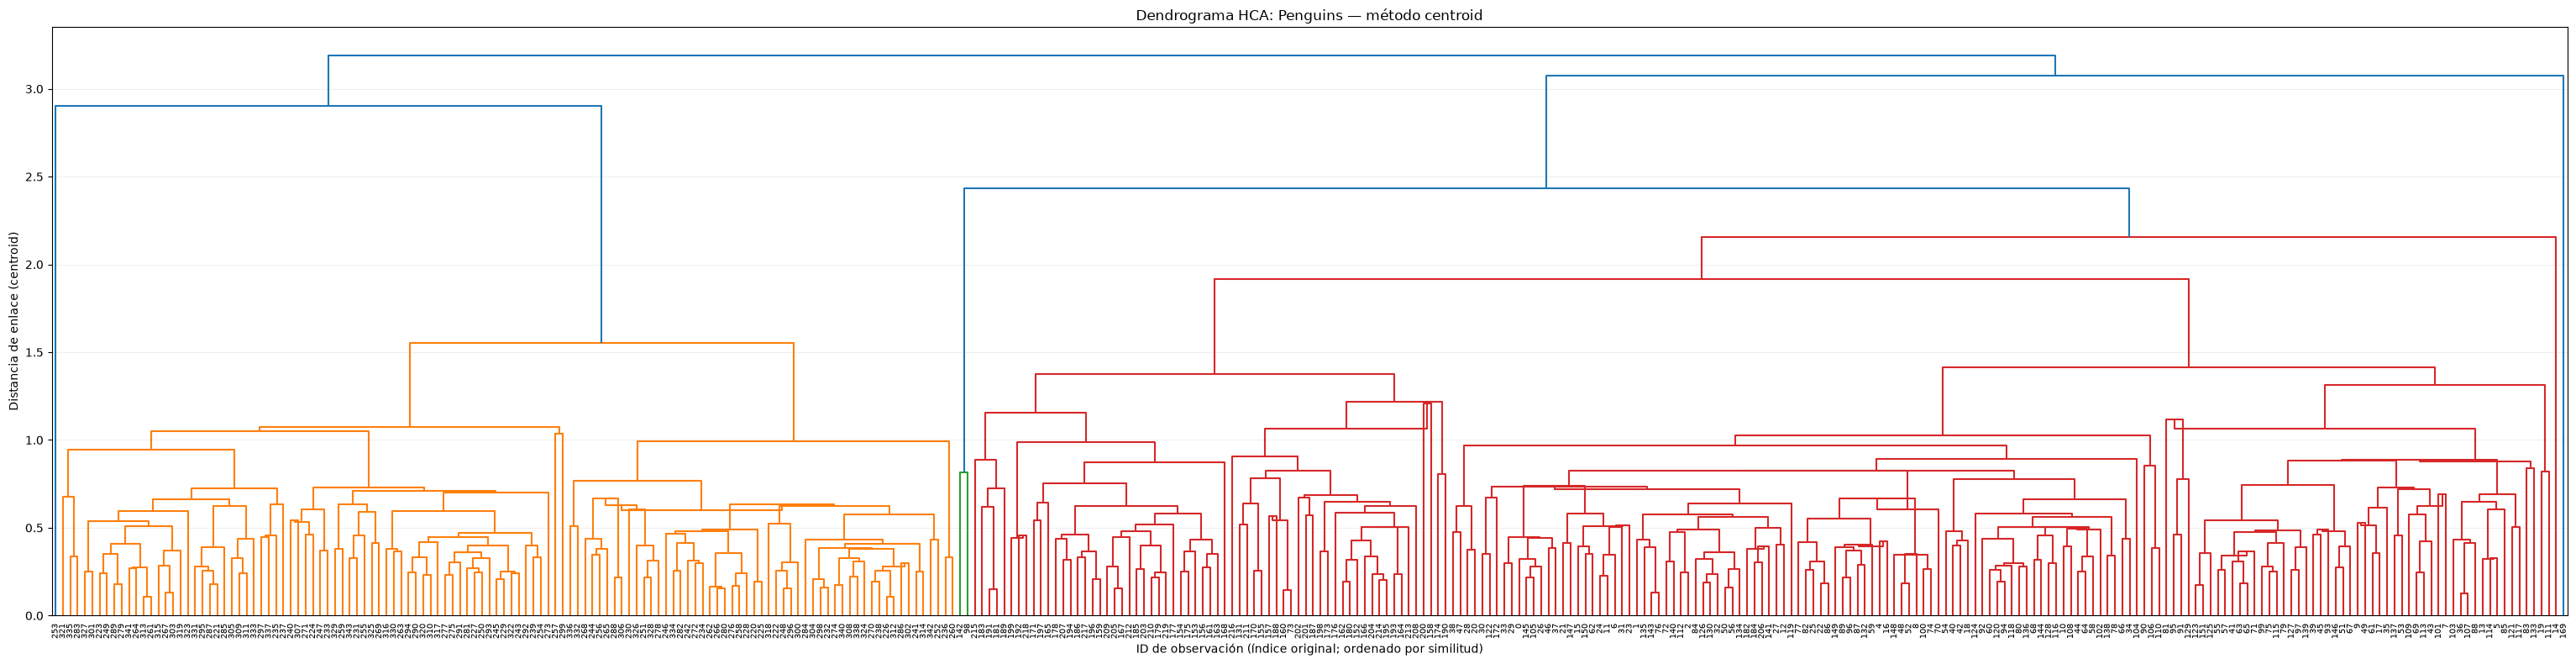

Guardado: penguins_dendrograms/penguins_dendrogram_median.png


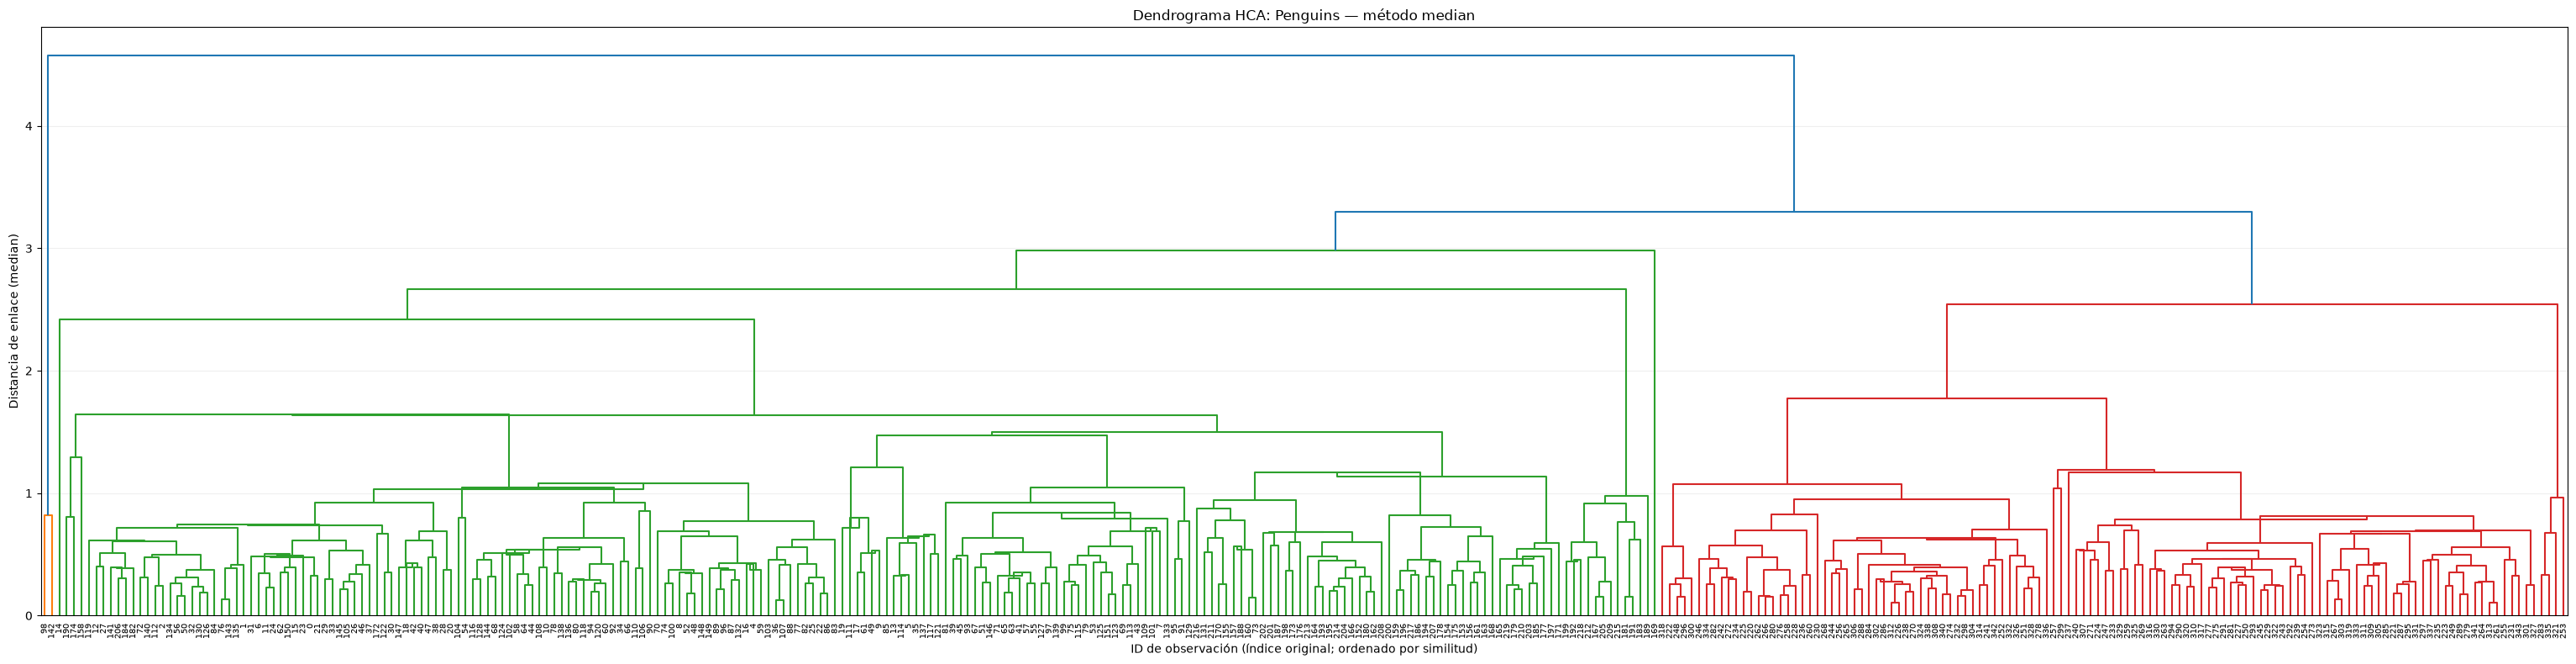

Guardado: penguins_dendrograms/penguins_dendrogram_ward.png


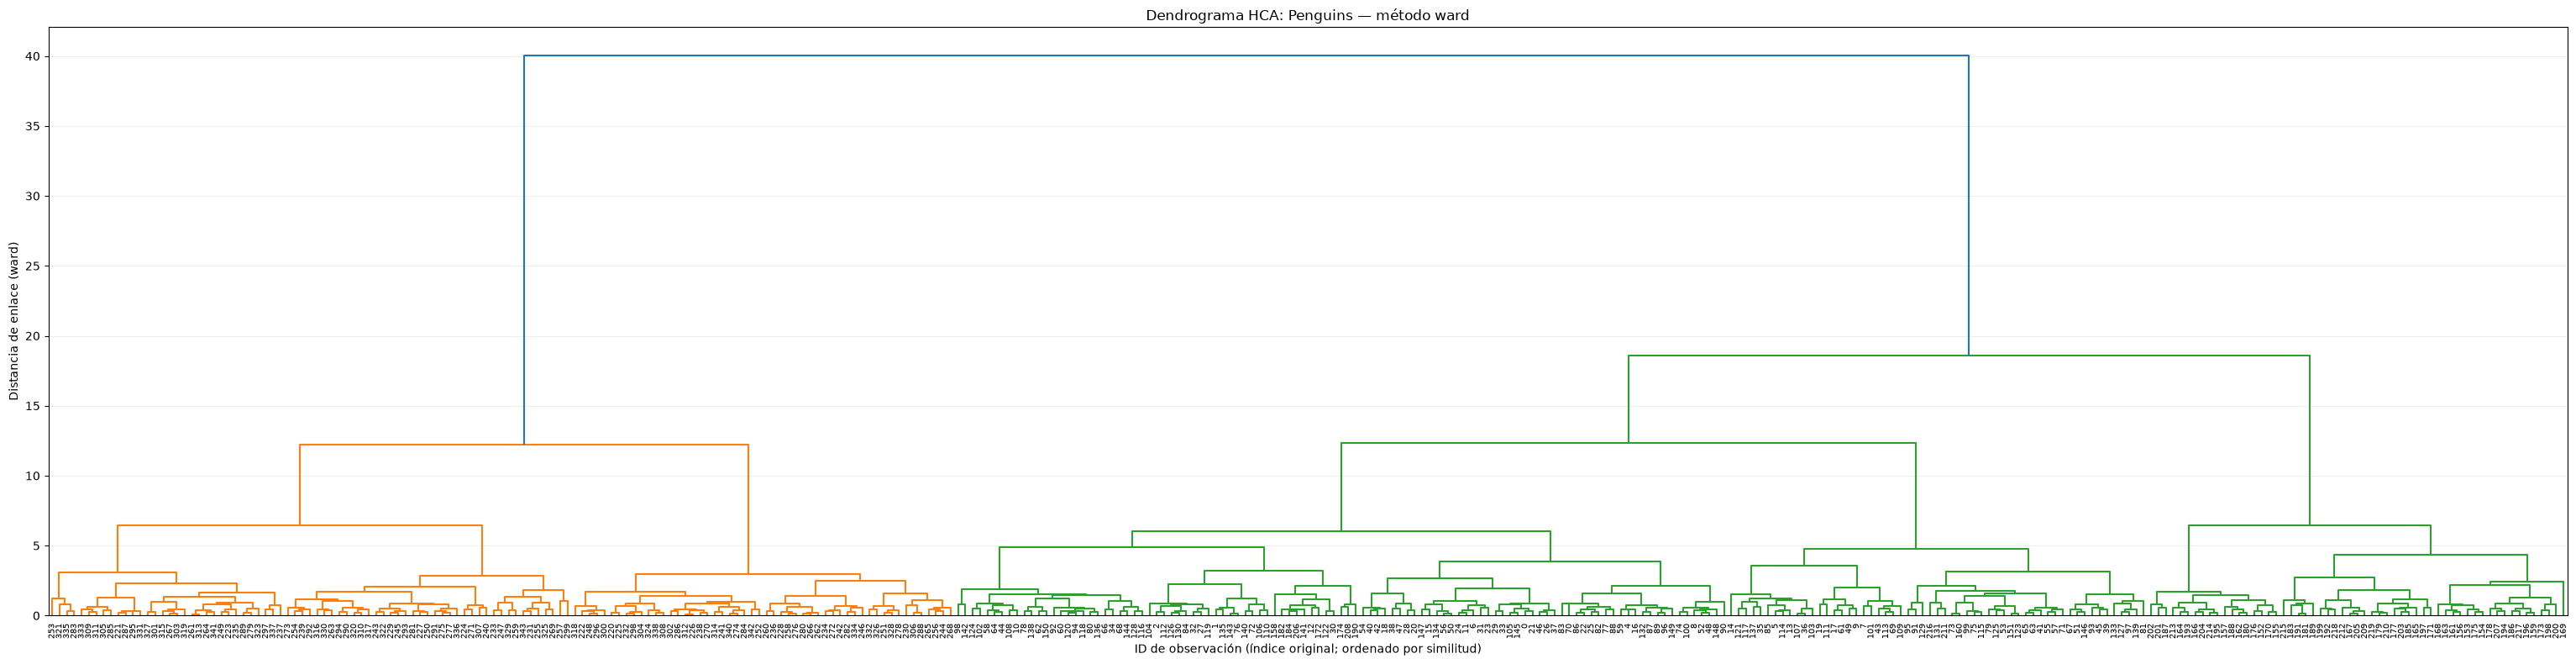

In [72]:
from pathlib import Path
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

linkage_methods = ["single", "complete", "average", "weighted", "centroid", "median", "ward"]
hca_linkages = {}
dendrogram_dir = Path("penguins_dendrograms")
dendrogram_dir.mkdir(exist_ok=True)
observation_ids = df_scaled.index.astype(str).tolist()

for method in linkage_methods:
    # Distancia euclídea para todos; necesaria para centroid, median y ward.
    hca_linkages[method] = linkage(
        df_scaled, method=method, metric="euclidean", optimal_ordering=True,
    )
    fig, ax = plt.subplots(figsize=(max(16, len(observation_ids) * 0.09), 8))
    dendrogram(
        hca_linkages[method], ax=ax, labels=observation_ids,
        leaf_rotation=90, leaf_font_size=7,
    )
    ax.set_title(f"Dendrograma HCA: Penguins — método {method}")
    ax.set_xlabel("ID de observación (índice original; ordenado por similitud)")
    ax.set_ylabel(f"Distancia de enlace ({method})")
    ax.grid(axis="y", alpha=0.2)
    fig.tight_layout()
    output_path = dendrogram_dir / f"penguins_dendrogram_{method}.png"
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    print(f"Guardado: {output_path}")
    plt.show()
    plt.close(fig)


## Clustering aglomerativo con best_k

Se utiliza enlace Ward, distancia euclídea y las cuatro features estandarizadas de KMeans.


In [73]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Mismos datos y número de clusters que KMeans.
hca_model = AgglomerativeClustering(
    n_clusters=best_k,
    linkage="average",
    metric="euclidean",
)
hca_labels = hca_model.fit_predict(df_scaled)

df_hca_clusters = df.copy()
df_hca_clusters["cluster"] = hca_labels

display(df_hca_clusters.head())
display(
    df_hca_clusters["cluster"].value_counts().sort_index()
    .rename("observaciones").to_frame()
)
hca_silhouette_score = silhouette_score(df_scaled, hca_labels)
print(f"Número de clusters: {hca_model.n_clusters_}")
print(f"Silhouette score HCA: {hca_silhouette_score:.4f}")


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,cluster
0,39.1,18.7,181.0,3750.0,0
1,39.5,17.4,186.0,3800.0,0
2,40.3,18.0,195.0,3250.0,0
4,36.7,19.3,193.0,3450.0,0
5,39.3,20.6,190.0,3650.0,0


,observaciones
cluster,
0,219
1,119
2,4


Número de clusters: 3
Silhouette score HCA: 0.4416


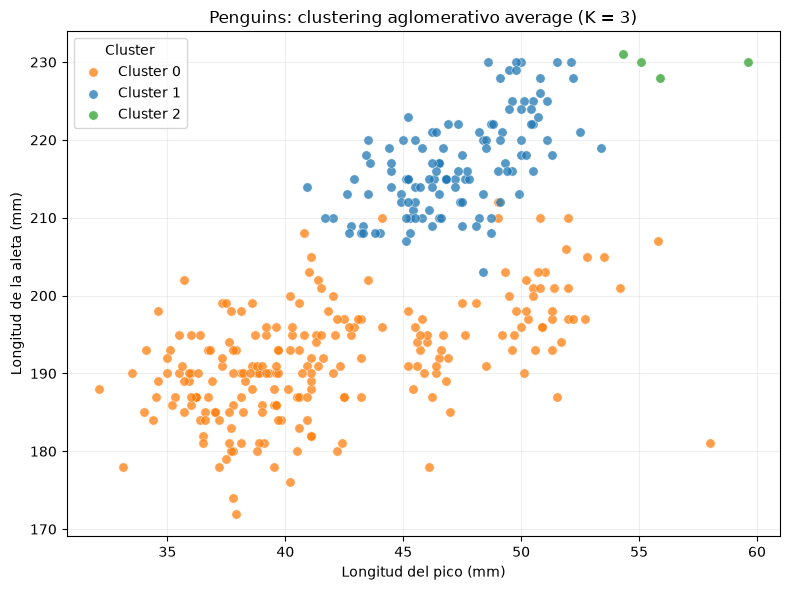

In [74]:
import matplotlib.pyplot as plt

# Proyección en dos features originales; HCA utiliza las cuatro estandarizadas.
hca_x_feature = "bill_length_mm"
hca_y_feature = "flipper_length_mm"
hca_k = hca_model.n_clusters_
hca_colors = (
    ["tab:orange", "tab:blue", "tab:green"] if hca_k == 3
    else [plt.get_cmap("turbo")(i / max(hca_k - 1, 1)) for i in range(hca_k)]
)

fig, ax = plt.subplots(figsize=(8, 6))
for color_index, cluster_id in enumerate(sorted(df_hca_clusters["cluster"].unique())):
    cluster_data = df_hca_clusters.loc[df_hca_clusters["cluster"] == cluster_id]
    ax.scatter(
        cluster_data[hca_x_feature], cluster_data[hca_y_feature],
        color=hca_colors[color_index], label=f"Cluster {cluster_id}",
        alpha=0.75, s=45, edgecolors="white", linewidths=0.4,
    )

ax.set_xlabel("Longitud del pico (mm)")
ax.set_ylabel("Longitud de la aleta (mm)")
ax.set_title(f"Penguins: clustering aglomerativo {hca_model.linkage} (K = {hca_k})")
ax.legend(title="Cluster")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig("penguins_hca_clusters_2d.png", dpi=300, bbox_inches="tight")
plt.show()


In [75]:
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Asignaciones por observación, alineadas mediante el índice original.
df_cluster_comparison = df.copy()
df_cluster_comparison["cluster_kmeans"] = df_clusters["cluster"]
df_cluster_comparison["cluster_hca"] = df_hca_clusters["cluster"]
display(df_cluster_comparison)

# Calidad de ambos modelos sobre las mismas cuatro features estandarizadas.
df_model_comparison = pd.DataFrame([
    {
        "modelo": "KMeans",
        "k": kmeans_model.n_clusters,
        "observaciones": len(df_clusters),
        "silhouette_score": silhouette_score(df_scaled, df_clusters["cluster"]),
    },
    {
        "modelo": f"HCA ({hca_model.linkage})",
        "k": hca_model.n_clusters_,
        "observaciones": len(df_hca_clusters),
        "silhouette_score": silhouette_score(df_scaled, df_hca_clusters["cluster"]),
    },
]).set_index("modelo")
display(df_model_comparison.round(4))

# Los IDs de cluster son arbitrarios: no se comparan por igualdad numérica.
# ARI mide concordancia entre particiones independientemente de sus IDs.
cluster_agreement = adjusted_rand_score(
    df_cluster_comparison["cluster_kmeans"],
    df_cluster_comparison["cluster_hca"],
)
print(f"Concordancia KMeans vs HCA (Adjusted Rand Index): {cluster_agreement:.4f}")
display(pd.crosstab(
    df_cluster_comparison["cluster_kmeans"],
    df_cluster_comparison["cluster_hca"],
))


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,cluster_kmeans,cluster_hca
0,39.1,18.7,181.0,3750.0,2,0
1,39.5,17.4,186.0,3800.0,2,0
2,40.3,18.0,195.0,3250.0,2,0
4,36.7,19.3,193.0,3450.0,2,0
5,39.3,20.6,190.0,3650.0,2,0
...,...,...,...,...,...,...
338,47.2,13.7,214.0,4925.0,1,1
340,46.8,14.3,215.0,4850.0,1,1
341,50.4,15.7,222.0,5750.0,1,1
342,45.2,14.8,212.0,5200.0,1,1


,k,observaciones,silhouette_score
modelo,,,
KMeans,3,342,0.4472
HCA (average),3,342,0.4416


Concordancia KMeans vs HCA (Adjusted Rand Index): 0.5974


cluster_hca,0,1,2
cluster_kmeans,,,
0,87,0,0
1,0,119,4
2,132,0,0


# DBSCAN

## Selección de eps: curva de distancia con 4 vecinos

Se utilizan las mismas cuatro features estandarizadas de KMeans y HCA. Se ordena la distancia al cuarto vecino, incluyendo la propia observación (distancia cero), de forma coherente con `min_samples=4` en DBSCAN. El cambio de pendiente orienta la elección de `eps`, expresado en las unidades del espacio estandarizado.


In [96]:
EPS = 0.8
MIN_SAMPLES = 5

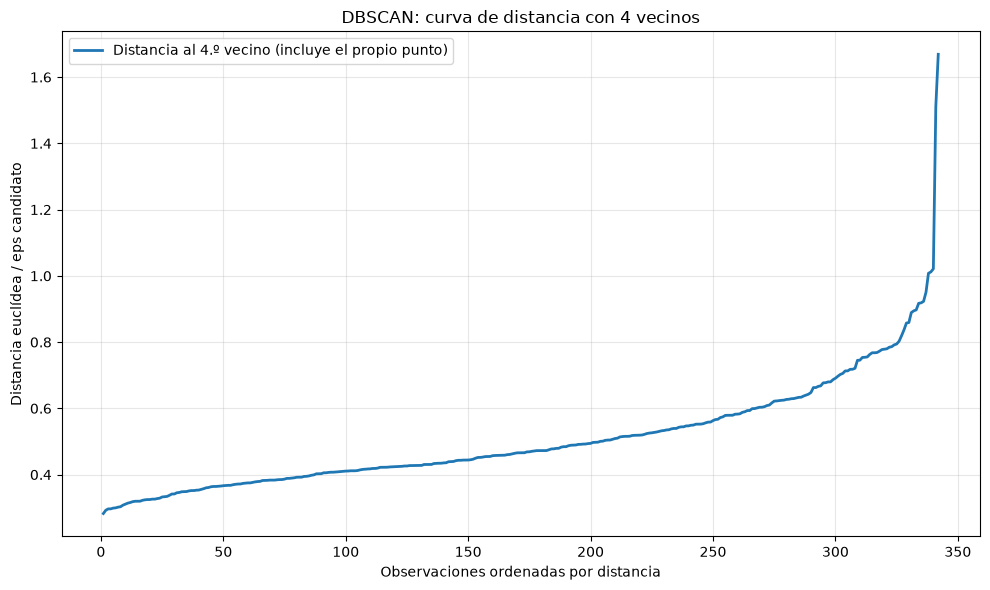

In [97]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors


neighbors_model = NearestNeighbors(n_neighbors=MIN_SAMPLES, metric="euclidean")
neighbors_model.fit(df_scaled)
# Al pasar X explícitamente, se incluye el propio punto entre los 4 vecinos.
neighbor_distances, neighbor_indices = neighbors_model.kneighbors(df_scaled)
k_distances = np.sort(neighbor_distances[:, -1])

eps_distance_table = pd.DataFrame({
    "observacion_ordenada": np.arange(1, len(k_distances) + 1),
    "distancia_4_vecinos": k_distances,
})

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(
    eps_distance_table["observacion_ordenada"], k_distances,
    color="tab:blue", linewidth=2, label="Distancia al 4.º vecino (incluye el propio punto)",
)
ax.set_xlabel("Observaciones ordenadas por distancia")
ax.set_ylabel("Distancia euclídea / eps candidato")
ax.set_title("DBSCAN: curva de distancia con 4 vecinos")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("penguins_dbscan_eps_4_neighbors.png", dpi=300, bbox_inches="tight")
plt.show()


In [98]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score


dbscan_model = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES, metric="euclidean")
dbscan_labels = dbscan_model.fit_predict(df_scaled)

df_dbscan_clusters = df.copy()
df_dbscan_clusters["cluster"] = dbscan_labels

dbscan_n_clusters = len(set(dbscan_labels) - {-1})
dbscan_noise_count = int((dbscan_labels == -1).sum())
print(f"eps: {EPS}; min_samples: {MIN_SAMPLES}")
print(f"Clusters encontrados: {dbscan_n_clusters}")
print(f"Observaciones de ruido (cluster -1): {dbscan_noise_count}")
display(df_dbscan_clusters.head())
display(
    df_dbscan_clusters["cluster"].value_counts().sort_index()
    .rename("observaciones").to_frame()
)

# Se excluye el ruido para evaluar la separación de los clusters encontrados.
dbscan_inliers = dbscan_labels != -1
if 2 <= dbscan_n_clusters < int(dbscan_inliers.sum()):
    dbscan_silhouette_score = silhouette_score(
        df_scaled.loc[dbscan_inliers], dbscan_labels[dbscan_inliers],
    )
    print(f"Silhouette score (sin ruido): {dbscan_silhouette_score:.4f}")
else:
    dbscan_silhouette_score = None
    print("Silhouette no definido: se requieren entre 2 y n-1 clusters sin ruido.")


eps: 0.8; min_samples: 5
Clusters encontrados: 2
Observaciones de ruido (cluster -1): 5


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,cluster
0,39.1,18.7,181.0,3750.0,0
1,39.5,17.4,186.0,3800.0,0
2,40.3,18.0,195.0,3250.0,0
4,36.7,19.3,193.0,3450.0,0
5,39.3,20.6,190.0,3650.0,0


,observaciones
cluster,
-1,5
0,216
1,121


Silhouette score (sin ruido): 0.5357


## Comparación de KMeans, HCA y DBSCAN

Los gráficos proyectan los clusters de cuatro dimensiones sobre dos features originales. El ruido DBSCAN aparece en gris. La tabla incluye silhouette sobre los puntos asignados por cada método y sobre una muestra común sin el ruido de DBSCAN, para comparar las mismas observaciones.


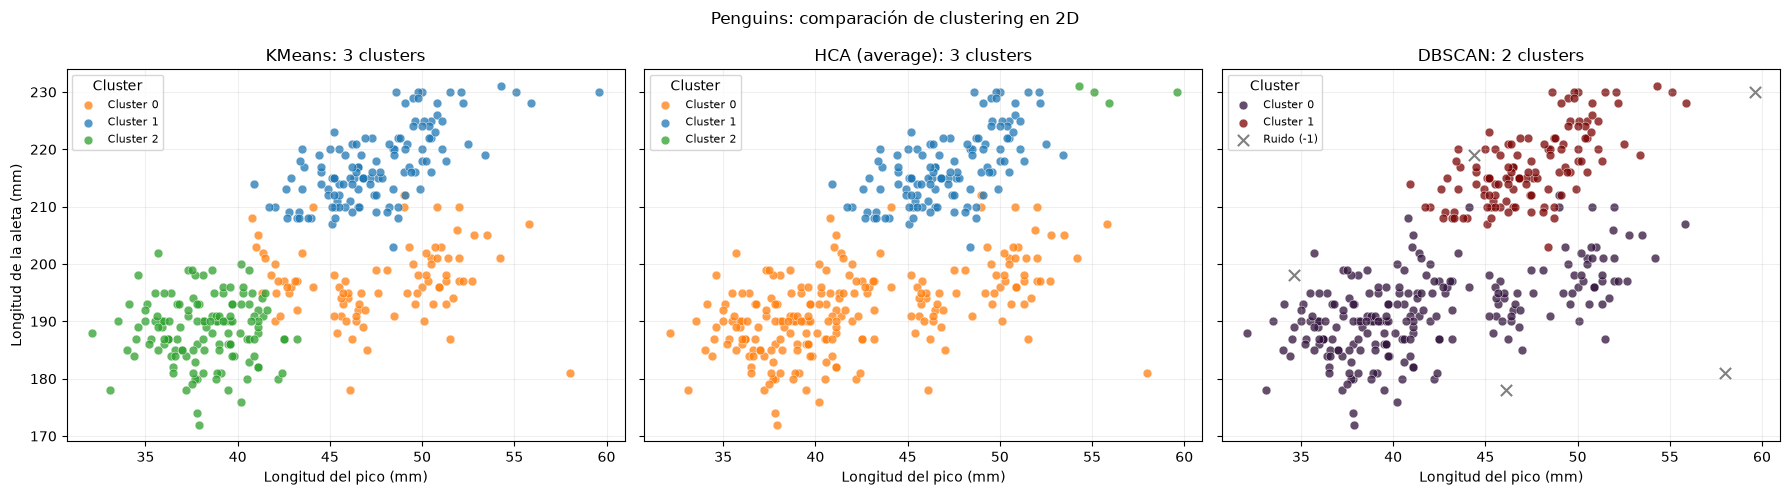

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,cluster_kmeans,cluster_hca,cluster_dbscan
0,39.1,18.7,181.0,3750.0,2,0,0
1,39.5,17.4,186.0,3800.0,2,0,0
2,40.3,18.0,195.0,3250.0,2,0,0
4,36.7,19.3,193.0,3450.0,2,0,0
5,39.3,20.6,190.0,3650.0,2,0,0
...,...,...,...,...,...,...,...
338,47.2,13.7,214.0,4925.0,1,1,1
340,46.8,14.3,215.0,4850.0,1,1,1
341,50.4,15.7,222.0,5750.0,1,1,1
342,45.2,14.8,212.0,5200.0,1,1,1


,clusters,observaciones,ruido,cobertura_pct,silhouette_sin_ruido_propio,silhouette_muestra_comun
modelo,,,,,,
KMeans,3,342,0,100.000,0.4472,0.4525
HCA (average),3,342,0,100.000,0.4416,0.4230
DBSCAN,2,342,5,98.538,0.5357,0.5357


Observaciones en la muestra común: 337


In [99]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

# Mismas features, escalas y observaciones en las tres visualizaciones.
clustering_results = {
    "KMeans": df_clusters["cluster"],
    f"HCA ({hca_model.linkage})": df_hca_clusters["cluster"],
    "DBSCAN": df_dbscan_clusters["cluster"],
}
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, (name, labels) in zip(axes, clustering_results.items()):
    cluster_ids = sorted(set(labels) - {-1})
    k = len(cluster_ids)
    colors = (["tab:orange", "tab:blue", "tab:green"] if k == 3
              else [plt.get_cmap("turbo")(i / max(k - 1, 1)) for i in range(k)])
    for i, cluster_id in enumerate(cluster_ids):
        points = df.loc[labels == cluster_id]
        ax.scatter(points["bill_length_mm"], points["flipper_length_mm"],
                   color=colors[i], label=f"Cluster {cluster_id}",
                   s=40, alpha=0.75, edgecolors="white", linewidths=0.4)
    noise = df.loc[labels == -1]
    if not noise.empty:
        ax.scatter(noise["bill_length_mm"], noise["flipper_length_mm"],
                   color="gray", marker="x", s=65, label="Ruido (-1)")
    ax.set_title(f"{name}: {k} clusters")
    ax.set_xlabel("Longitud del pico (mm)")
    ax.grid(alpha=0.2)
    ax.legend(title="Cluster", fontsize=8)
axes[0].set_ylabel("Longitud de la aleta (mm)")
fig.suptitle("Penguins: comparación de clustering en 2D")
fig.tight_layout()
fig.savefig("penguins_clustering_comparison_2d.png", dpi=300, bbox_inches="tight")
plt.show()

# Los números y colores de cluster no implican equivalencia entre modelos.
df_cluster_comparison = df.copy()
for column, labels in zip(
    ["cluster_kmeans", "cluster_hca", "cluster_dbscan"], clustering_results.values()
):
    df_cluster_comparison[column] = labels
display(df_cluster_comparison)

# Comparación adicional sobre las mismas observaciones: excluir el ruido DBSCAN
# de los tres modelos, sin reajustarlos.
common_mask = df_dbscan_clusters["cluster"] != -1

def valid_silhouette(features, labels):
    if 2 <= len(np.unique(labels)) < len(labels):
        return silhouette_score(features, labels)
    return np.nan

comparison_rows = []
for name, labels in clustering_results.items():
    inliers = labels != -1
    comparison_rows.append({
        "modelo": name,
        "clusters": len(set(labels) - {-1}),
        "observaciones": len(labels),
        "ruido": int((~inliers).sum()),
        "cobertura_pct": inliers.mean() * 100,
        "silhouette_sin_ruido_propio": valid_silhouette(df_scaled.loc[inliers], labels.loc[inliers]),
        "silhouette_muestra_comun": valid_silhouette(df_scaled.loc[common_mask], labels.loc[common_mask]),
    })
df_model_comparison = pd.DataFrame(comparison_rows).set_index("modelo")
display(df_model_comparison.round(4))
print(f"Observaciones en la muestra común: {common_mask.sum()}")


## Comparación externa con species

`species` se conserva como referencia y no se usa para entrenar. Las tablas muestran composición por cluster y concordancia con las especies mediante ARI y NMI. Una buena separación geométrica (silhouette) no garantiza recuperar las especies.


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,cluster_kmeans,cluster_hca,cluster_dbscan,species
0,39.1,18.7,181.0,3750.0,2,0,0,Adelie
1,39.5,17.4,186.0,3800.0,2,0,0,Adelie
2,40.3,18.0,195.0,3250.0,2,0,0,Adelie
4,36.7,19.3,193.0,3450.0,2,0,0,Adelie
5,39.3,20.6,190.0,3650.0,2,0,0,Adelie
...,...,...,...,...,...,...,...,...
338,47.2,13.7,214.0,4925.0,1,1,1,Gentoo
340,46.8,14.3,215.0,4850.0,1,1,1,Gentoo
341,50.4,15.7,222.0,5750.0,1,1,1,Gentoo
342,45.2,14.8,212.0,5200.0,1,1,1,Gentoo



KMeans: cluster vs especie (-1 = ruido)


species,Adelie,Chinstrap,Gentoo
cluster_kmeans,,,
0,24,63,0
1,0,0,123
2,127,5,0


species,Adelie,Chinstrap,Gentoo
cluster_kmeans,,,
0,27.6,72.4,0.0
1,0.0,0.0,100.0
2,96.2,3.8,0.0


  Cluster 0: predomina Chinstrap (63/87, 72.4%)
  Cluster 1: predomina Gentoo (123/123, 100.0%)
  Cluster 2: predomina Adelie (127/132, 96.2%)

HCA (average): cluster vs especie (-1 = ruido)


...

species,Adelie,Chinstrap,Gentoo
cluster_dbscan,,,
-1,1,2,2
0,150,66,0
1,0,0,121


species,Adelie,Chinstrap,Gentoo
cluster_dbscan,,,
-1,20.0,40.0,40.0
0,69.4,30.6,0.0
1,0.0,0.0,100.0


  Ruido: predomina Chinstrap (2/5, 40.0%)
  Cluster 0: predomina Adelie (150/216, 69.4%)
  Cluster 1: predomina Gentoo (121/121, 100.0%)


,ARI_todas,NMI_todas,ARI_muestra_comun,NMI_muestra_comun
modelo,,,,
KMeans,0.7928,0.7855,0.7903,0.7834
HCA (average),0.6375,0.7445,0.6440,0.7496
DBSCAN,0.6467,0.7299,0.6575,0.7680


Mayor ARI/NMI indica mayor concordancia con species; no depende del ID del cluster.
En 'todas', el ruido DBSCAN se trata como un grupo; la muestra común lo excluye de los tres modelos.


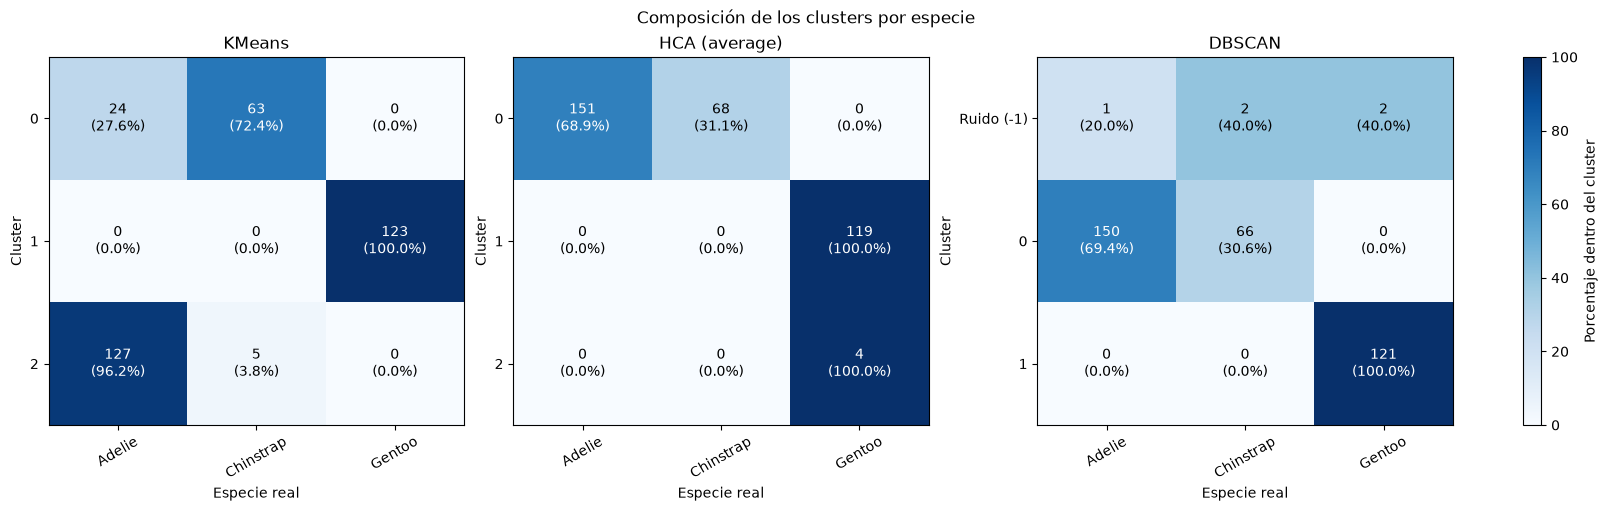

In [100]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
import matplotlib.pyplot as plt
import numpy as np

# Alinear por índice tras dropna; species no entra al escalado ni al clustering.
df_cluster_comparison["species"] = df_original.loc[df_cluster_comparison.index, "species"]
display(df_cluster_comparison)
species_labels = df_cluster_comparison["species"]
species_common_mask = df_cluster_comparison["cluster_dbscan"] != -1
species_tables = {}
species_metric_rows = []

for name, column in [
    ("KMeans", "cluster_kmeans"),
    (f"HCA ({hca_model.linkage})", "cluster_hca"),
    ("DBSCAN", "cluster_dbscan"),
]:
    labels = df_cluster_comparison[column]
    counts = pd.crosstab(labels, species_labels)
    species_tables[name] = counts
    print(f"\n{name}: cluster vs especie (-1 = ruido)")
    display(counts)
    display(counts.div(counts.sum(axis=1), axis=0).mul(100).round(1))
    species_metric_rows.append({
        "modelo": name,
        "ARI_todas": adjusted_rand_score(species_labels, labels),
        "NMI_todas": normalized_mutual_info_score(species_labels, labels),
        "ARI_muestra_comun": adjusted_rand_score(species_labels.loc[species_common_mask], labels.loc[species_common_mask]),
        "NMI_muestra_comun": normalized_mutual_info_score(species_labels.loc[species_common_mask], labels.loc[species_common_mask]),
    })
    for cluster_id, row in counts.iterrows():
        majority_species = row.idxmax()
        print(f"  {'Ruido' if cluster_id == -1 else f'Cluster {cluster_id}'}: "
              f"predomina {majority_species} ({row.max()}/{row.sum()}, {100 * row.max()/row.sum():.1f}%)")

df_species_comparison = pd.DataFrame(species_metric_rows).set_index("modelo")
display(df_species_comparison.round(4))
print("Mayor ARI/NMI indica mayor concordancia con species; no depende del ID del cluster.")
print("En 'todas', el ruido DBSCAN se trata como un grupo; la muestra común lo excluye de los tres modelos.")

fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
for ax, (name, counts) in zip(axes, species_tables.items()):
    percentages = counts.div(counts.sum(axis=1), axis=0).mul(100)
    image = ax.imshow(percentages, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(len(counts.columns)), counts.columns, rotation=30)
    ax.set_yticks(range(len(counts.index)), ["Ruido (-1)" if i == -1 else str(i) for i in counts.index])
    ax.set_title(name)
    ax.set_xlabel("Especie real")
    ax.set_ylabel("Cluster")
    for i in range(len(counts.index)):
        for j in range(len(counts.columns)):
            ax.text(j, i, f"{counts.iloc[i, j]}\n({percentages.iloc[i, j]:.1f}%)",
                    ha="center", va="center", color="white" if percentages.iloc[i, j] > 50 else "black")
fig.colorbar(image, ax=axes, label="Porcentaje dentro del cluster")
fig.suptitle("Composición de los clusters por especie")
fig.savefig("penguins_clusters_vs_species.png", dpi=300, bbox_inches="tight")
plt.show()


### Interpretación de la configuración actual

- **KMeans (K=3)** recupera mejor las especies (ARI=0.7928). Separa todos los Gentoo en un cluster; los otros dos corresponden principalmente a Adelie y Chinstrap, con cierta mezcla.
- **HCA (average, K=3)** mezcla los 151 Adelie con los 68 Chinstrap y divide Gentoo en grupos de 119 y 4. Sus tres clusters no equivalen a las tres especies (ARI=0.6375).
- **DBSCAN (eps=0.8, min_samples=5)** separa Gentoo de un grupo mixto Adelie/Chinstrap y detecta 5 puntos de ruido (ARI=0.6467 incluyendo ruido como grupo).

Aunque DBSCAN obtiene mayor silhouette, KMeans coincide mejor con las especies. Silhouette evalúa separación geométrica; ARI/NMI evalúan concordancia con la referencia biológica. Los IDs y colores de los clusters son arbitrarios. Estos valores corresponden a la configuración actual; deben revisarse si cambian los parámetros.
